In [106]:
import numpy as np
import matplotlib.pyplot as plt

In [107]:
stages = 14
dP = 35_000
RPM = 30000
omega = RPM/30 * np.pi

r_tip = 0.1086
r_hub = 0.03676
w0 = 130
rho = 1.32

doR = 0.5 

sigma_m = 1.0 #solidity at mass average radius



In [108]:
# stages = 14
# dP = 25811
# RPM = 20000
# omega = RPM/30 * np.pi

# r_tip = 0.1086
# r_hub = 0.03676
# w0 = 154.15
# rho =  1.2975

# doR = 0.5 

# sigma_m = 1.0 #solidity at mass average radius

In [109]:
itr = 1_000
r = np.linspace(r_hub,r_tip,itr)
rm = np.sqrt((r_tip**2 + r_hub**2)/2)

In [110]:
R = 1 - rm**2 / r**2 * (1 - doR)
Rh = R[0]

V_theta_1_h = w0* 1/2 * (2*omega*r_hub/w0*(1 - Rh) - 1/(omega*r_hub/w0)*(dP/(rho*w0**2))) 
V_theta_2_h = w0* 1/2 * (2*omega*r_hub/w0*(1 - Rh) + 1/(omega*r_hub/w0)*(dP/(rho*w0**2))) 


V_theta_1 = r_hub * V_theta_1_h / r
V_theta_2 = r_hub * V_theta_2_h / r 

theta_1 = np.arctan(V_theta_1/w0) 
theta_2 = np.arctan(V_theta_2/w0)

beta_1 = np.arctan(omega*r/w0 - V_theta_1/w0)
beta_2 = np.arctan(omega*r/w0 - V_theta_2/w0)

sigma = rm / r * sigma_m

D_rotor = 1 - np.cos(beta_1)/np.cos(beta_2) + 1/(2*sigma) * np.abs(np.tan(beta_1)-np.tan(beta_2))*1 /np.cos(beta_1)

theta_3 = theta_1
D_stator = 1 - np.cos(theta_2)/np.cos(theta_3) + np.abs(np.tan(theta_3) - np.tan(theta_2))/(2*sigma*1/np.cos(theta_2))



# D_rotor = 1 - np.cos(beta_1)/np.cos(beta_2) + 1/(2*sigma) * (np.tan(beta_1)-np.tan(beta_2))*np.cos(beta_1)

# theta_3 = theta_1
# D_stator = 1 - np.cos(theta_2)/np.cos(theta_3) + (np.tan(theta_3) - np.tan(theta_2))/(2*sigma*1/np.cos(theta_2))

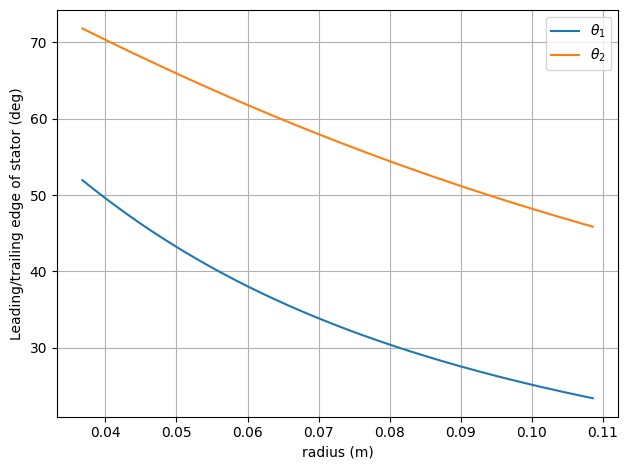

In [111]:
fig = plt.figure(1)
ax = plt.axes()
ax.plot(r,np.rad2deg(theta_1),label = r'$\theta_1$')
ax.plot(r,np.rad2deg(theta_2),label = r'$\theta_2$')


ax.set_ylabel('Leading/trailing edge of stator (deg)')
ax.set_xlabel(r'radius (m)')
plt.tight_layout()
ax.grid()
ax.legend()
plt.savefig(r'stator_angles.png', dpi=1200)

plt.show()

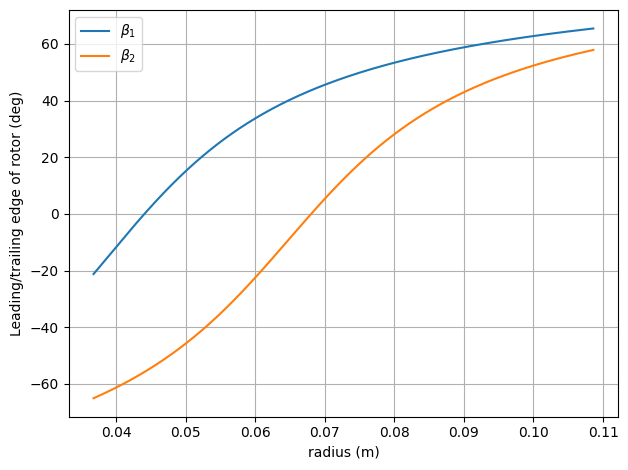

In [112]:
fig = plt.figure(2)
ax = plt.axes()
ax.plot(r,np.rad2deg(beta_1),label = r'$\beta_1$')
ax.plot(r,np.rad2deg(beta_2),label = r'$\beta_2$')


ax.set_ylabel('Leading/trailing edge of rotor (deg)')
ax.set_xlabel(r'radius (m)')
plt.tight_layout()
ax.legend()
ax.grid()
plt.savefig(r'rotor_angles.png', dpi=1200)


plt.show()

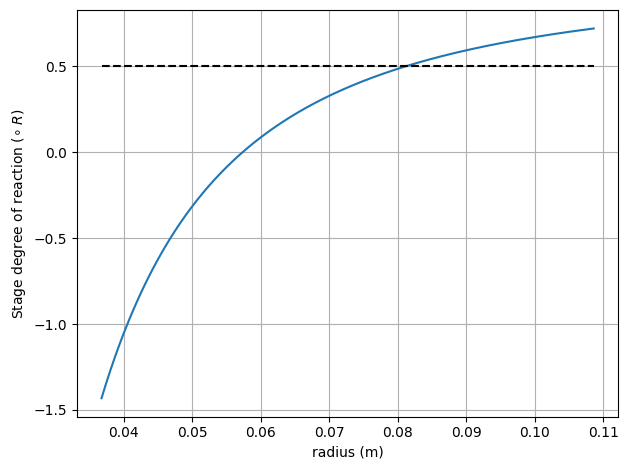

In [113]:
fig = plt.figure(3)


ax = plt.axes()
ax.plot(r,R)
line = np.ones(itr) * doR
ax.plot(r,line,ls='--',color = 'k')


ax.set_ylabel(r'Stage degree of reaction $ \left(\circ^ R \right)$')
ax.set_xlabel(r'radius (m)')
plt.grid()
plt.tight_layout()
# plt.legend()
plt.savefig(r'dor.png', dpi=1200)

plt.show()

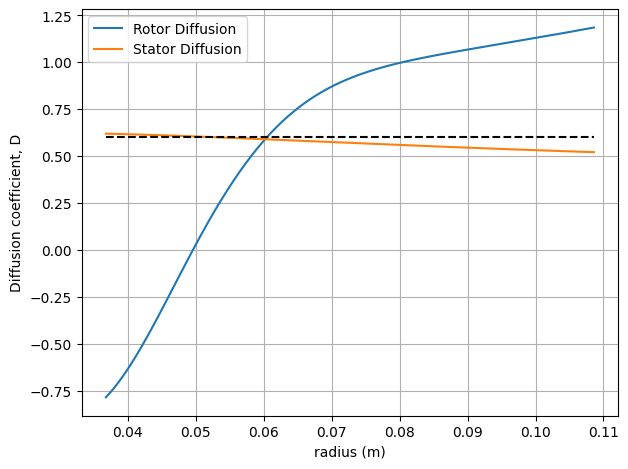

In [114]:




fig = plt.figure(4)


ax = plt.axes()
ax.plot(r,D_rotor, label = "Rotor Diffusion")

ax.plot(r,D_stator,label = "Stator Diffusion")
line = np.ones(itr) * 0.6
ax.plot(r,line,ls='--',color = 'k')


ax.set_ylabel(r'Diffusion coefficient, D')
ax.set_xlabel(r'radius (m)')
plt.grid()
plt.tight_layout()
plt.legend()
plt.savefig(r'diffusion.png', dpi=1200)

plt.show()

In [115]:
chord = 0.020376 # m



Cm = rm * 2*np.pi

blades = Cm / chord
print(f'{blades = }')

blades = 24.99945201781663
